# 🔍 Eigen-CAM: Explainable CNN Image Classification

This notebook demonstrates:
1. Training a small CNN on **CIFAR-10**
2. Generating **Eigen-CAM** saliency maps to explain model decisions
3. Visualizing heatmap overlays and comparing across layers

**Eigen-CAM** uses SVD on convolutional activation maps to extract the principal
component — the dominant spatial pattern the network focuses on.

## 1. Setup & Imports

In [1]:
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Local imports
from model import SmallCNN
from eigen_cam import EigenCAM
from train import train, CIFAR10_MEAN, CIFAR10_STD, CIFAR10_CLASSES, get_dataloaders
from utils import denormalize, overlay_heatmap, show_eigen_cam_grid, show_layer_comparison

%matplotlib inline
plt.rcParams['figure.dpi'] = 120

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


## 2. Train or Load Model

If a checkpoint exists, we load it. Otherwise, we train from scratch.

In [2]:
CHECKPOINT_PATH = 'checkpoints/best_model.pth'

model = SmallCNN(num_classes=10).to(device)

if os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Loaded checkpoint (val acc: {checkpoint['val_acc']:.2f}%)")
else:
    print('No checkpoint found. Training from scratch...')
    model = train(epochs=10, lr=0.001)
    model = model.to(device)

model.eval()
print(f'Model has {sum(p.numel() for p in model.parameters()):,} parameters')

Loaded checkpoint (val acc: 68.47%)
Model has 94,986 parameters


## 3. Load Test Data

In [3]:
# Load CIFAR-10 test set
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

test_dataset = datasets.CIFAR10(
    root='./data', train=False, download=True, transform=test_transform
)

test_loader = DataLoader(test_dataset, batch_size=16, shuffle=True)

# Grab a batch of test images
sample_images, sample_labels = next(iter(test_loader))
print(f'Sample batch shape: {sample_images.shape}')
print(f'Labels: {[CIFAR10_CLASSES[l] for l in sample_labels[:8]]}')

Sample batch shape: torch.Size([16, 3, 32, 32])
Labels: ['horse', 'dog', 'automobile', 'dog', 'automobile', 'dog', 'automobile', 'frog']


c:\Users\mohammadjad\Desktop\Si\venv\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


## 4. Preview Sample Images

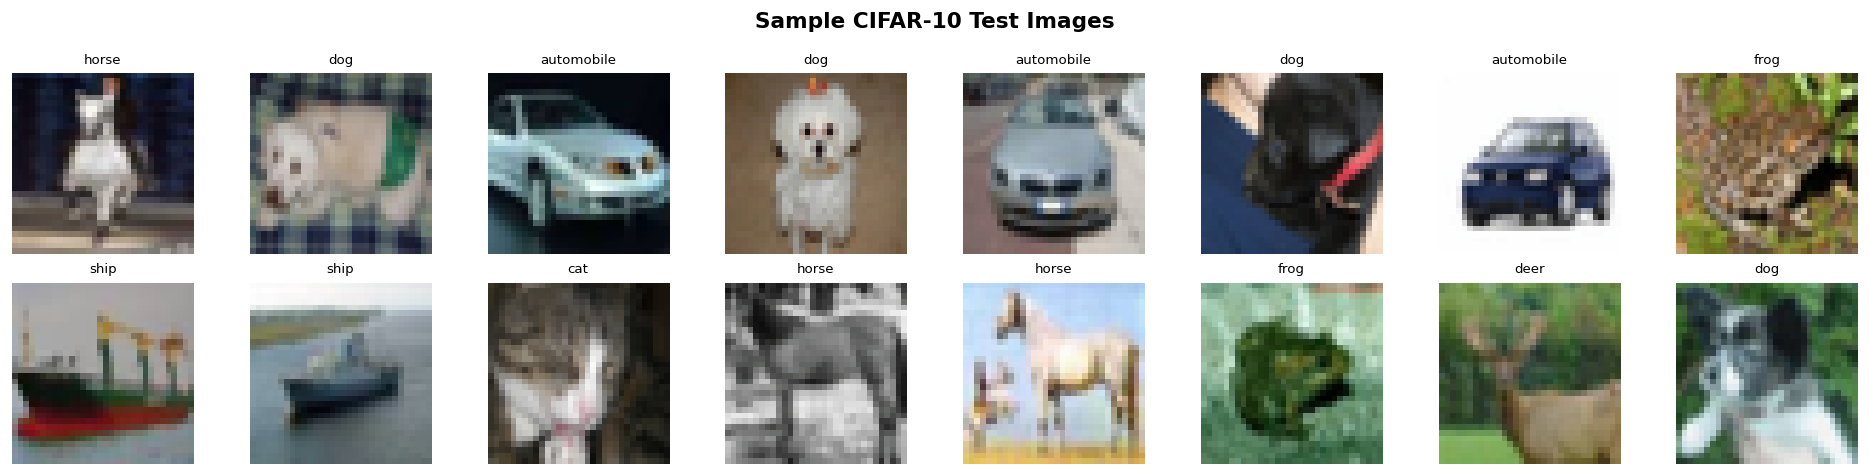

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(16):
    row, col = divmod(i, 8)
    img = denormalize(sample_images[i])
    axes[row, col].imshow(img)
    axes[row, col].set_title(CIFAR10_CLASSES[sample_labels[i]], fontsize=8)
    axes[row, col].axis('off')

plt.suptitle('Sample CIFAR-10 Test Images', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Generate Eigen-CAM Heatmaps

We extract activations from the **last convolutional layer** (Block 3),
perform SVD, and take the first principal component as the saliency map.

In [5]:
# Initialize Eigen-CAM on the last conv layer
target_layer = model.get_cam_target_layer()
eigen_cam = EigenCAM(model, target_layer)

# Generate CAMs for the sample batch
cams = eigen_cam.generate_batch(sample_images, target_size=(32, 32))

# Get model predictions
with torch.no_grad():
    outputs = model(sample_images.to(device))
    _, predicted = outputs.max(1)
    pred_labels = predicted.cpu().numpy()

print(f'Generated {len(cams)} Eigen-CAM maps')
print(f'CAM shape: {cams[0].shape}, range: [{cams[0].min():.3f}, {cams[0].max():.3f}]')

Generated 16 Eigen-CAM maps
CAM shape: (32, 32), range: [0.054, 0.974]


## 6. Visualize Heatmap Overlays

Each row shows: **Original** → **Eigen-CAM Heatmap** → **Overlay with Prediction**

Green = correct, Red = incorrect predictions.

Saved figure to outputs/eigen_cam_grid.png


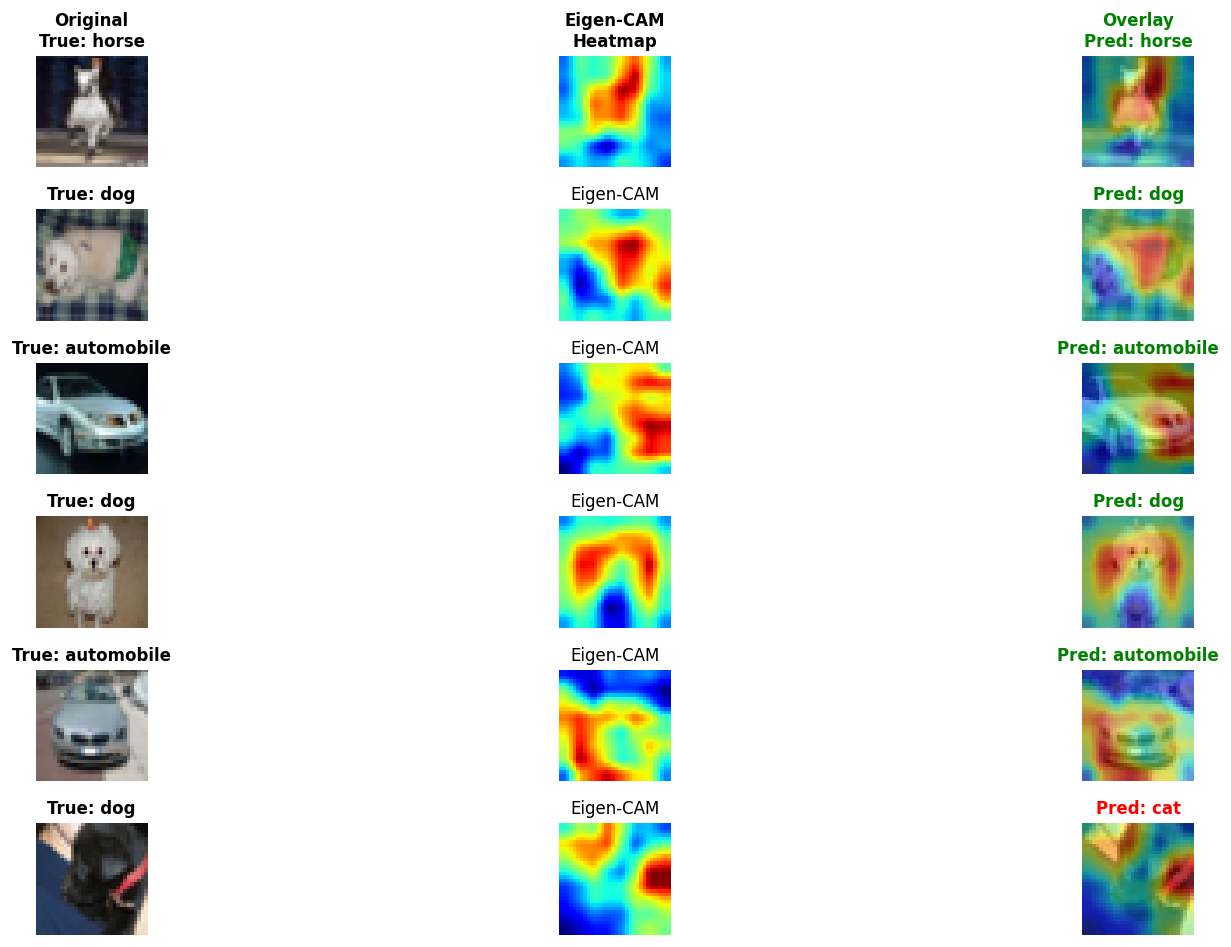

In [6]:
os.makedirs('outputs', exist_ok=True)

# Show first 6 samples
n_show = 6
display_images = [denormalize(sample_images[i]) for i in range(n_show)]
display_cams = cams[:n_show]
display_labels = [CIFAR10_CLASSES[sample_labels[i]] for i in range(n_show)]
display_preds = [CIFAR10_CLASSES[pred_labels[i]] for i in range(n_show)]

show_eigen_cam_grid(
    images=display_images,
    cams=display_cams,
    labels=display_labels,
    predictions=display_preds,
    save_path='outputs/eigen_cam_grid.png',
)

## 7. Per-Class Eigen-CAM Examples

Show one correctly classified example per CIFAR-10 class.

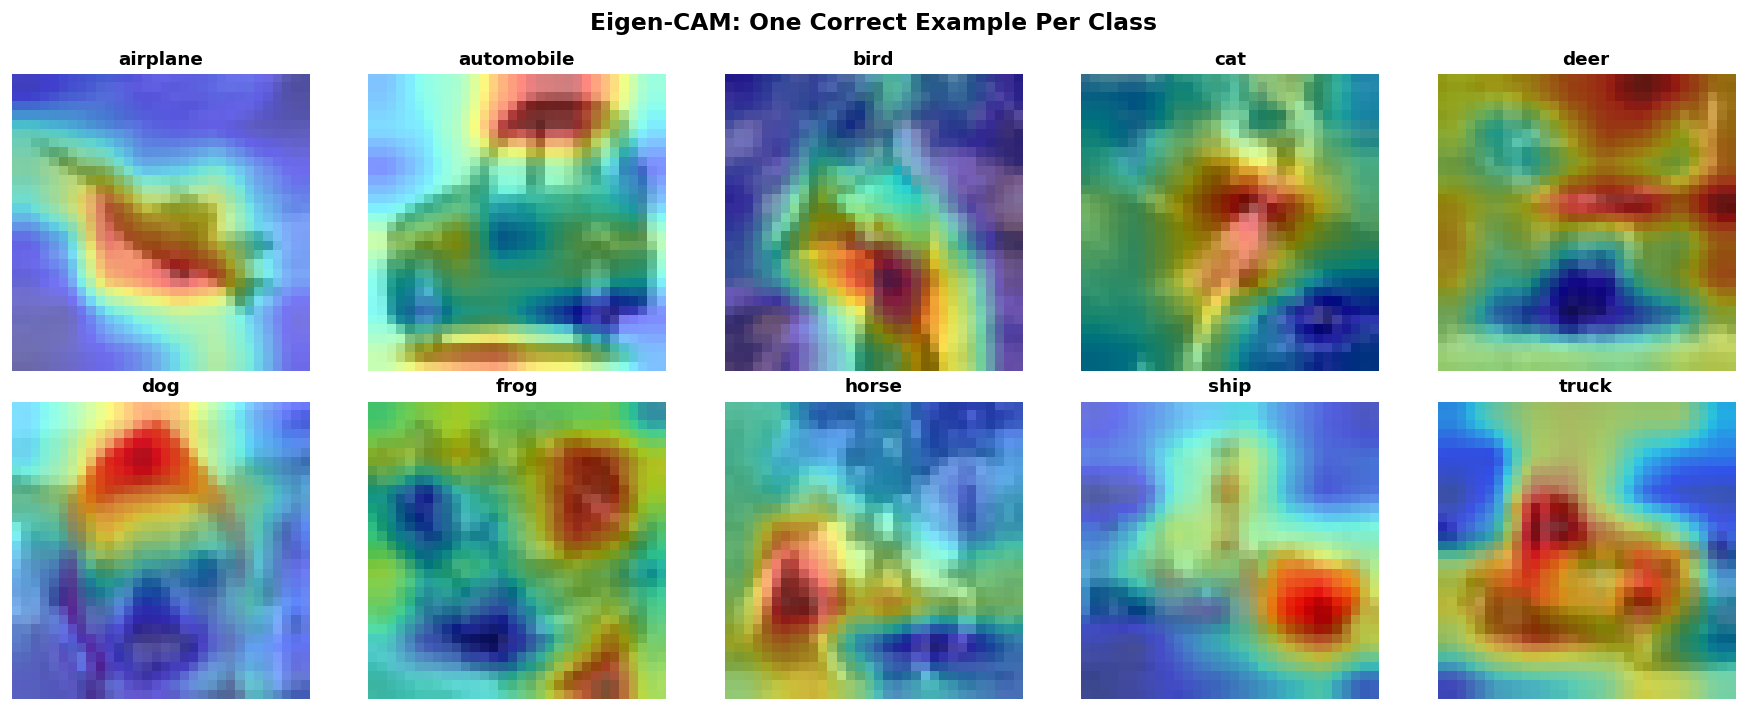

Saved per-class visualization to outputs/per_class_eigen_cam.png


In [7]:
# Collect one correct example per class
class_examples = {}  # class_idx → (image_tensor, label)

with torch.no_grad():
    for images, labels in DataLoader(test_dataset, batch_size=64, shuffle=True):
        outputs = model(images.to(device))
        _, preds = outputs.max(1)
        preds = preds.cpu()

        for i in range(len(labels)):
            cls = labels[i].item()
            if cls not in class_examples and preds[i].item() == cls:
                class_examples[cls] = images[i]

        if len(class_examples) == 10:
            break

# Generate CAMs for each class
per_class_images = []
per_class_cams = []
per_class_labels = []

for cls_idx in range(10):
    img_tensor = class_examples[cls_idx]
    cam = eigen_cam.generate(img_tensor.unsqueeze(0), target_size=(32, 32))
    per_class_images.append(denormalize(img_tensor))
    per_class_cams.append(cam)
    per_class_labels.append(CIFAR10_CLASSES[cls_idx])

# Display 2 rows of 5 classes each
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i in range(10):
    row, col = divmod(i, 5)
    overlay = overlay_heatmap(per_class_images[i], per_class_cams[i], alpha=0.5)
    axes[row, col].imshow(overlay)
    axes[row, col].set_title(per_class_labels[i], fontsize=11, fontweight='bold')
    axes[row, col].axis('off')

plt.suptitle('Eigen-CAM: One Correct Example Per Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/per_class_eigen_cam.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved per-class visualization to outputs/per_class_eigen_cam.png')

## 8. Eigen-CAM Across Different Layers

Compare what the network "sees" at each convolutional block.
Earlier layers attend to edges/textures; deeper layers focus on semantic regions.

Saved figure to outputs/layer_comparison_0.png


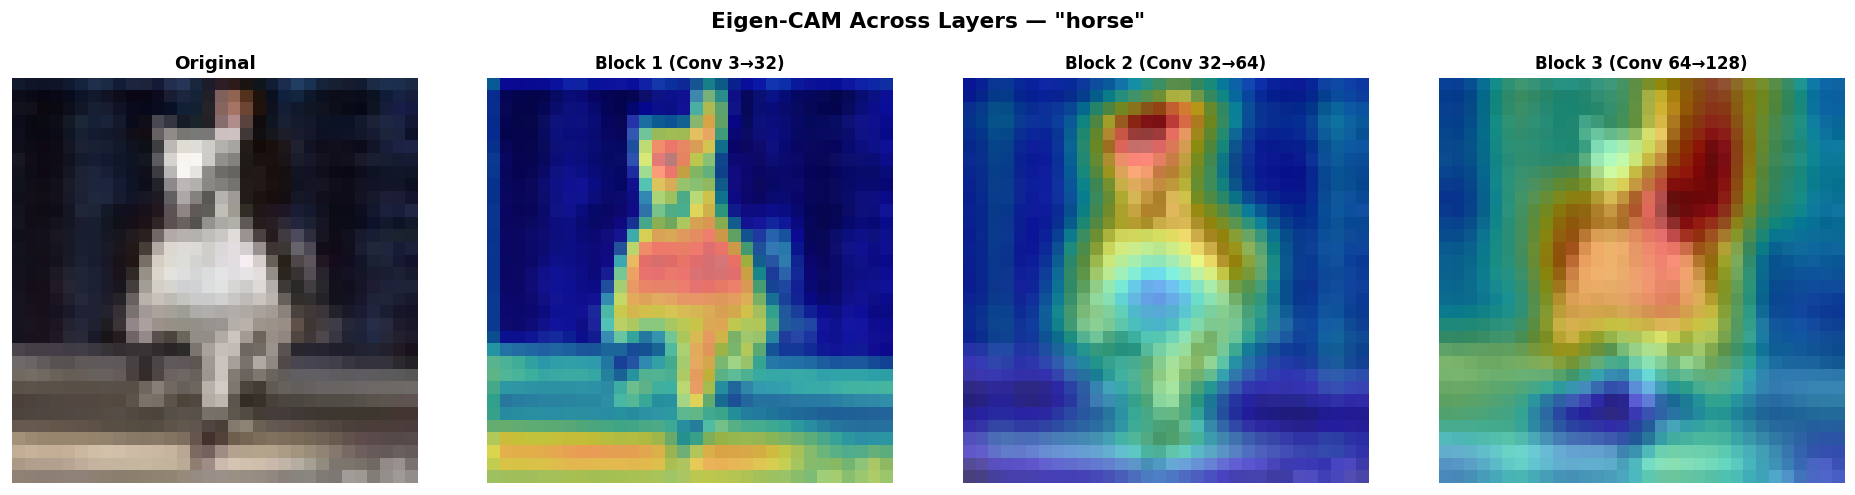

Saved figure to outputs/layer_comparison_3.png


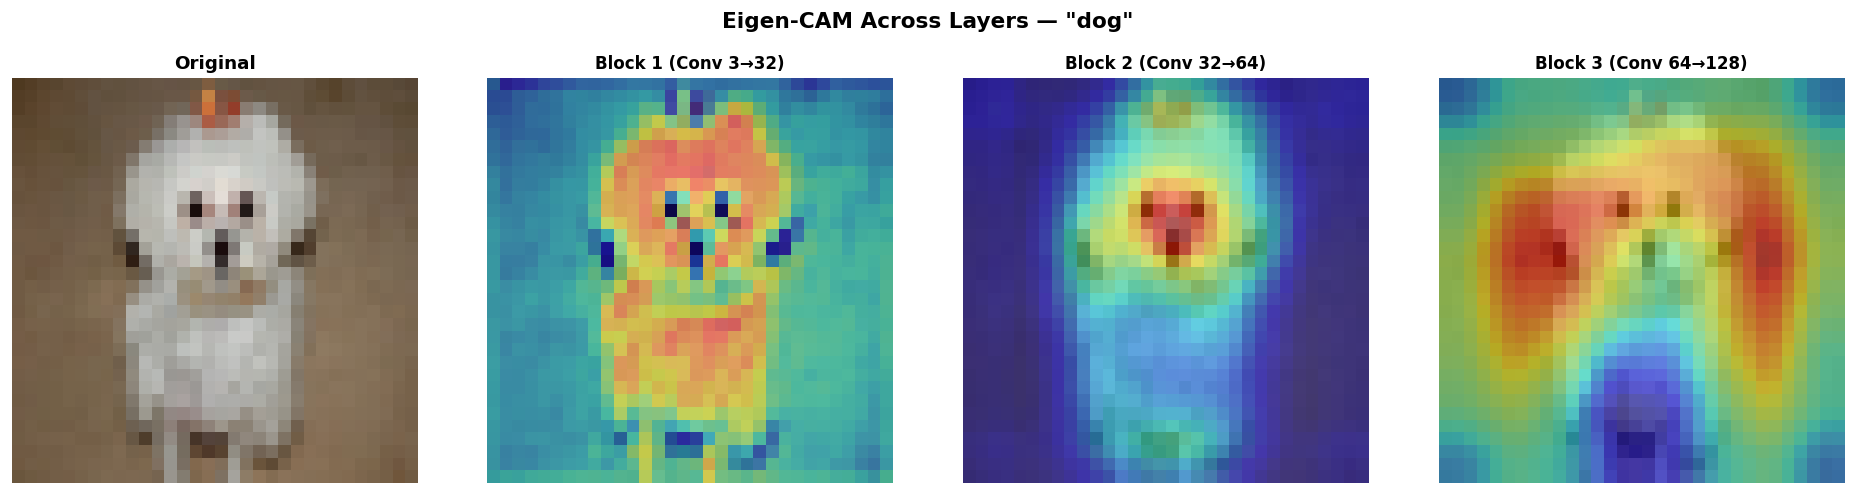

Saved figure to outputs/layer_comparison_7.png


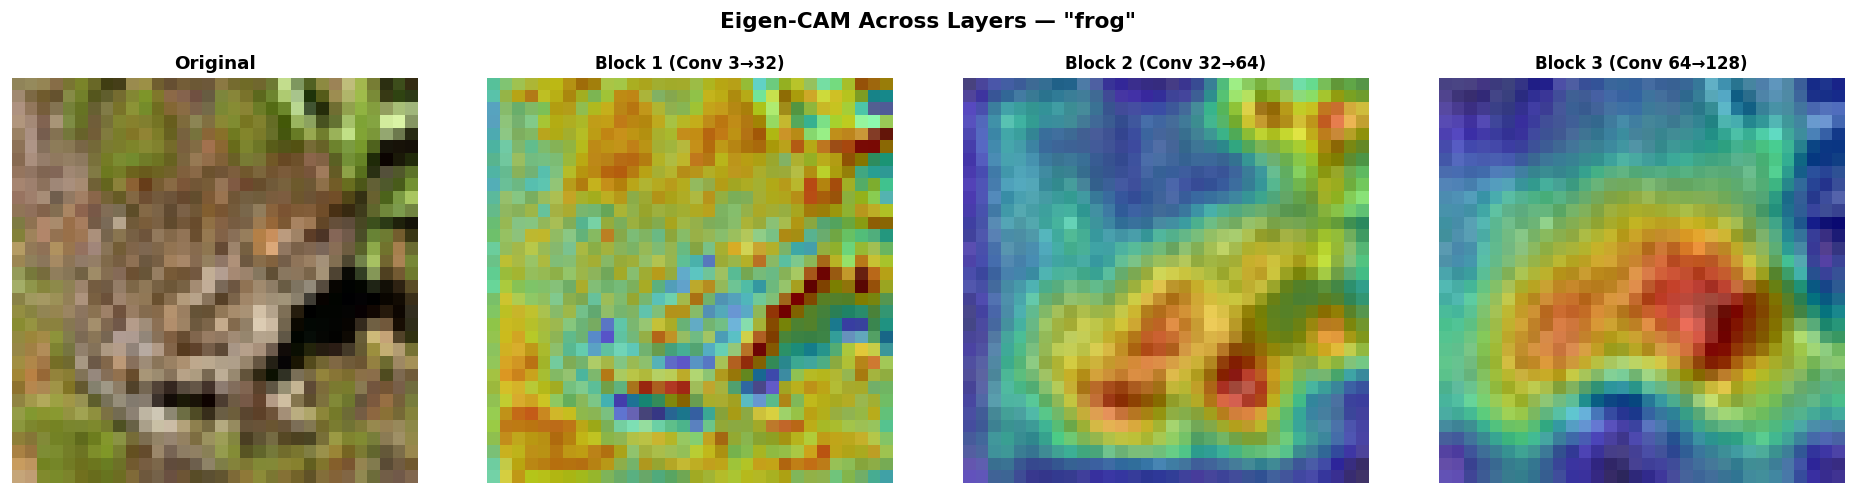

In [8]:
# Clean up previous hook
eigen_cam.remove_hook()

# Define target layers from each conv block
layer_map = {
    'Block 1 (Conv 3→32)': model.features[0],  # First conv
    'Block 2 (Conv 32→64)': model.features[4],  # Second conv
    'Block 3 (Conv 64→128)': model.features[8],  # Third conv
}

# Pick 3 sample images for comparison
comparison_indices = [0, 3, 7]

for idx in comparison_indices:
    img_tensor = sample_images[idx]
    img_display = denormalize(img_tensor)
    true_label = CIFAR10_CLASSES[sample_labels[idx]]

    cams_per_layer = {}
    for name, layer in layer_map.items():
        cam_obj = EigenCAM(model, layer)
        cam = cam_obj.generate(img_tensor.unsqueeze(0), target_size=(32, 32))
        cams_per_layer[name] = cam
        cam_obj.remove_hook()

    show_layer_comparison(
        image=img_display,
        cams_dict=cams_per_layer,
        title=f'Eigen-CAM Across Layers — "{true_label}"',
        save_path=f'outputs/layer_comparison_{idx}.png',
    )

## 9. Model Accuracy Report

In [9]:
from train import evaluate
import torch.nn as nn

_, test_loader_eval = get_dataloaders(batch_size=128)
criterion = nn.CrossEntropyLoss()

val_loss, val_acc = evaluate(model, test_loader_eval, criterion, device)
print(f'\n══════════════════════════════════════')
print(f'  Test Loss:     {val_loss:.4f}')
print(f'  Test Accuracy: {val_acc:.2f}%')
print(f'══════════════════════════════════════')

c:\Users\mohammadjad\Desktop\Si\venv\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



══════════════════════════════════════
  Test Loss:     0.9029
  Test Accuracy: 68.47%
══════════════════════════════════════


## 10. Summary

### What is Eigen-CAM?

**Eigen-CAM** generates saliency maps by computing the **principal component** (via SVD)
of the activation maps from a convolutional layer:

1. Forward pass → capture activations `A` of shape `(C, H, W)`
2. Reshape to `(C, H×W)` and compute SVD
3. Take the first right singular vector → reshape to `(H, W)`
4. Normalize and upscale to input image size

### Key Properties
- **Class-agnostic**: Does not require gradients or class-specific information
- **Efficient**: No backward pass needed, just one forward pass + SVD
- **Layer-flexible**: Can be applied to any convolutional layer

### Observations
- **Deeper layers** produce more semantically meaningful (object-focused) saliency maps
- **Earlier layers** highlight low-level features like edges and textures
- Heatmaps generally align well with the object of interest in the image